In [2]:
import numpy as np
import math as m
import pickle
import matplotlib.pyplot as plt

# loading dataset

In [3]:
def load_dataset(file_path):

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")
    
    train_set, valid_set, test_set = data

    X_train, y_train = train_set
    X_val, y_val = valid_set
    X_test, y_test = test_set
    
    print("MNIST dataset was loaded successfully with the shapes:\n")
    print(f"X_train:{X_train.shape} \ny_train:{y_train.shape}")
    print("---------------------------")
    print(f"X_val: {X_val.shape} \ny_val: {y_val.shape}")
    print("---------------------------")
    print(f"X_test: {X_test.shape} \ny_test: {y_test.shape}")

    return X_train, y_train, X_val, y_val, X_test, y_test

In [4]:
X_train, y_train, X_val, y_val, X_test, y_test = load_dataset('mnist.pkl')

MNIST dataset was loaded successfully with the shapes:

X_train:(50000, 784) 
y_train:(50000,)
---------------------------
X_val: (10000, 784) 
y_val: (10000,)
---------------------------
X_test: (10000, 784) 
y_test: (10000,)


# 2.1) visulize dataset

In [5]:
def plot_mnist_samples(X, y, num_samples=5):
    """
    Plots `num_samples` random images from each class (0-9) in MNIST dataset.
    
    Args:
        X: np.ndarray of shape (num_examples, 784) or (num_examples, 28, 28)
        y: np.ndarray of labels of shape (num_examples,)
        num_samples: int, number of images per class to display
    """
    # Reshape if flattened
    if X.ndim == 2:
        X = X.reshape(-1, 28, 28)
    
    classes = np.unique(y)
    plt.figure(figsize=(num_samples*2, len(classes)*2))
    
    for i, cls in enumerate(classes):
        # Get indices of images with label `cls`
        cls_indices = np.where(y == cls)[0]
        # Pick `num_samples` random indices
        selected_indices = np.random.choice(cls_indices, num_samples, replace=False)
        
        for j, idx in enumerate(selected_indices):
            plt_idx = i * num_samples + j + 1
            plt.subplot(len(classes), num_samples, plt_idx)
            plt.imshow(X[idx], cmap='gray')
            plt.axis('off')
            if j == 0:
                plt.ylabel(cls, fontsize=12)
    
    plt.tight_layout()
    plt.show()

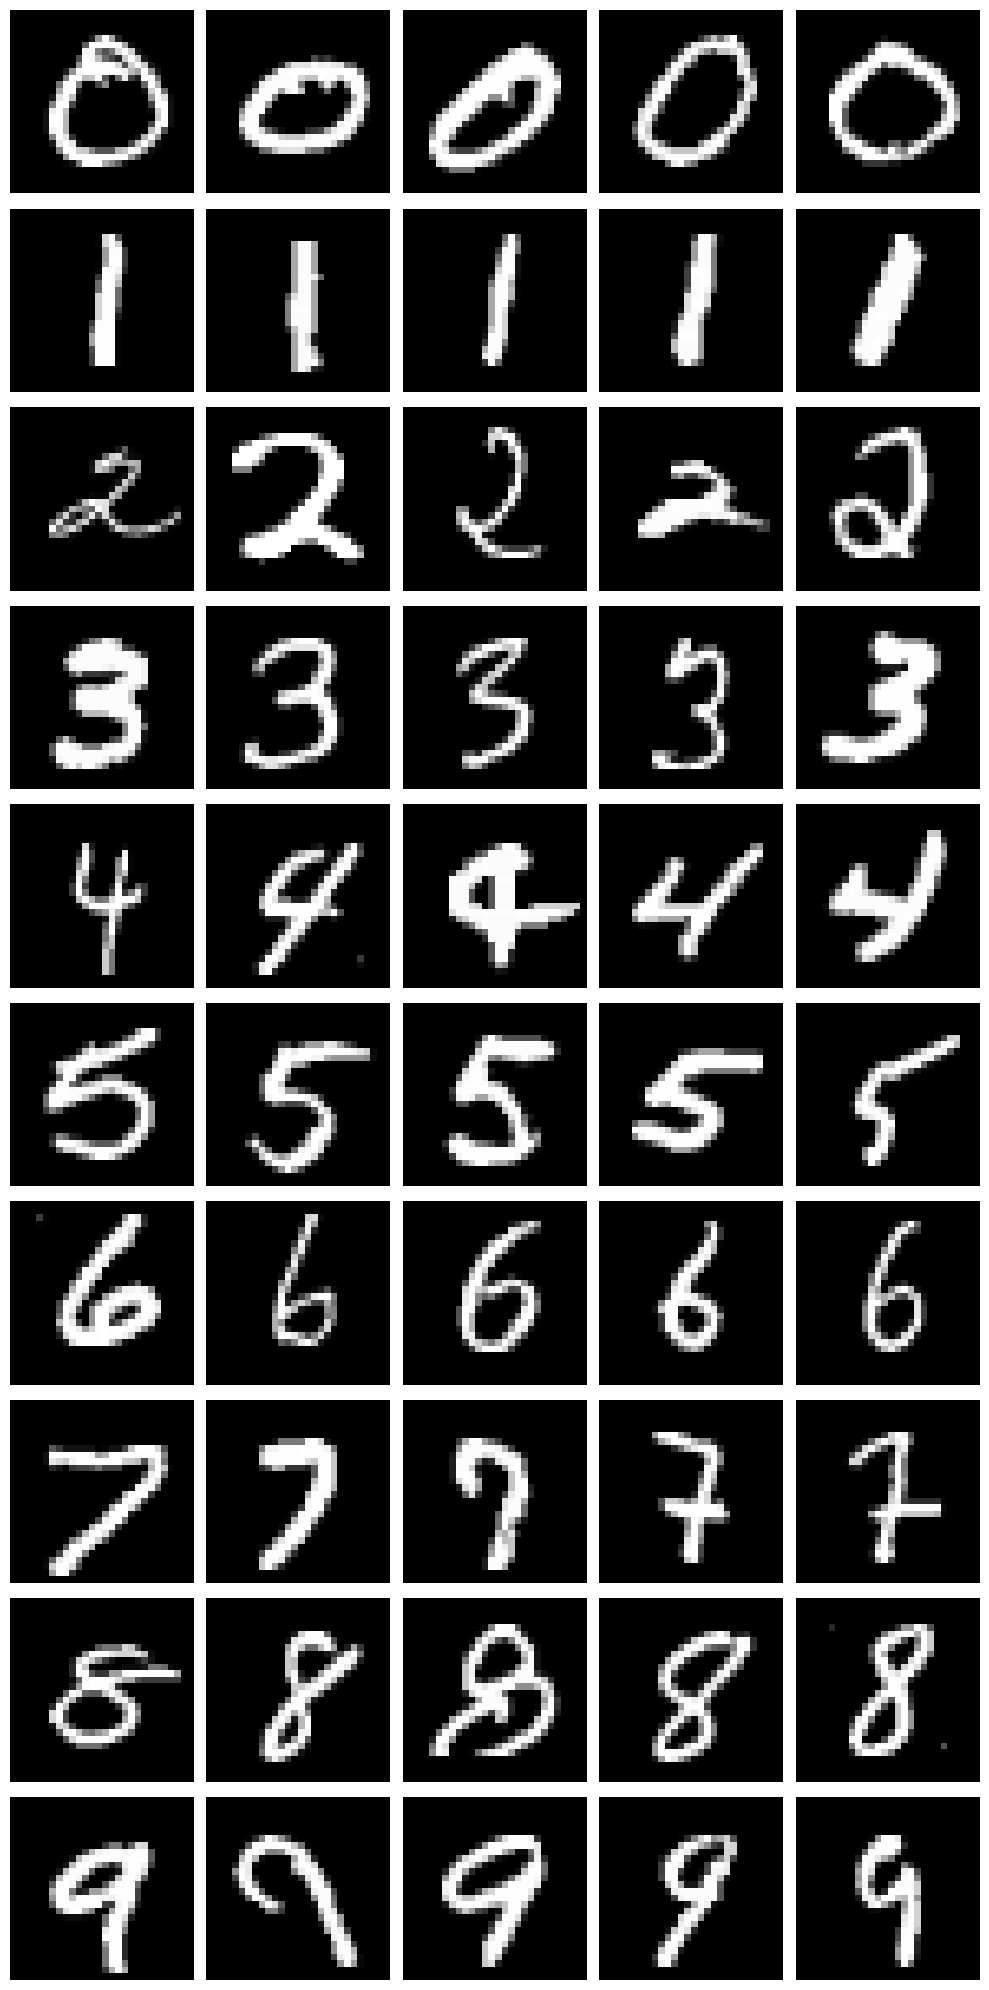

In [6]:
plot_mnist_samples(X_train, y_train, num_samples=5)

# 2.2) distribution

In [7]:
def plot_class_distributions(y_train, y_val, y_test):
    """
    Plots side-by-side histograms of the MNIST class distributions
    for train, validation, and test sets.
    """
    classes = np.arange(10)  # MNIST digits 0-9
    train_counts = np.bincount(y_train, minlength=10)
    val_counts = np.bincount(y_val, minlength=10)
    test_counts = np.bincount(y_test, minlength=10)
    
    width = 0.25  # width of each bar
    x = np.arange(len(classes))
    
    plt.figure(figsize=(10,6))
    plt.bar(x - width, train_counts, width=width, label="Train", color='skyblue')
    plt.bar(x, val_counts, width=width, label="Validation", color='orange')
    plt.bar(x + width, test_counts, width=width, label="Test", color='green')
    
    plt.xlabel("Digit Class")
    plt.ylabel("Number of Samples")
    plt.title("MNIST Class Distributions")
    plt.xticks(classes)
    plt.legend()
    plt.show()

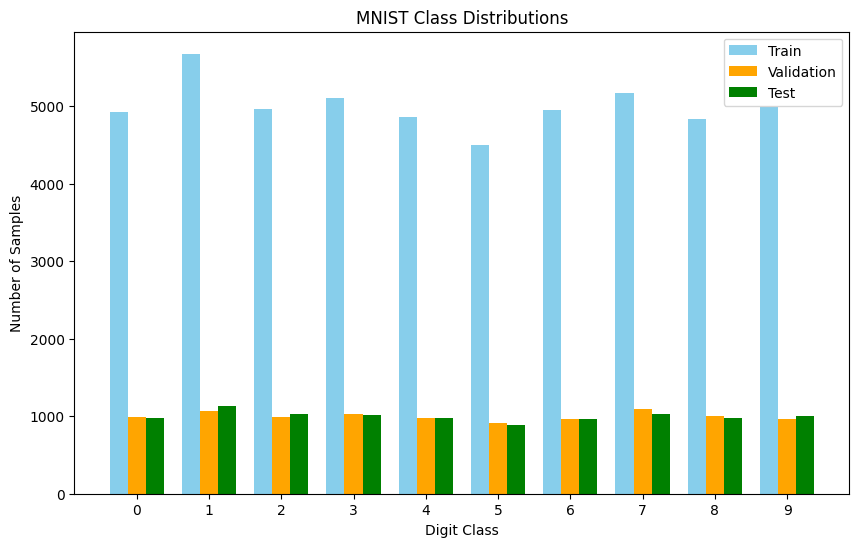

In [8]:
plot_class_distributions(y_train, y_val, y_test)

In [9]:
def relative_imbalance(y_train):
    train_counts = np.bincount(y_train, minlength=10)
    train_sum, train_max, train_min = np.sum(train_counts), np.max(train_counts), np.min(train_counts)
    diff = train_max - train_min
    rel_imbalance = (diff / train_sum) * 100
    return rel_imbalance

In [10]:
relative_imbalance(y_train)

np.float64(2.344)

# 2.3, 2.4) check shapes / flatten images

In [11]:
# Check that all images have the same number of features
def check_flattened_shapes(*arrays):
    for i, X in enumerate(arrays):
        print(f"Array {i+1}: {X.shape[0]} samples, {X.shape[1]} features per sample")
    # Optional assertion
    num_features = arrays[0].shape[1]
    assert all(X.shape[1] == num_features for X in arrays), "Dimension mismatch detected!"

In [12]:
check_flattened_shapes(X_train, X_val, X_test)

Array 1: 50000 samples, 784 features per sample
Array 2: 10000 samples, 784 features per sample
Array 3: 10000 samples, 784 features per sample


In [13]:
X_train[0].shape

(784,)

# 2.5) train, val split

In [14]:
def train_val_split(X, y, val_fraction=0.1, random_seed=None):
    """
    Splits X and y into train/validation sets with stratification.
    
    Args:
        X: np.ndarray, shape (num_samples, num_features)
        y: np.ndarray, shape (num_samples,)
        val_fraction: float, fraction of data to use as validation
        random_seed: int or None, for reproducibility
    
    Returns:
        X_train, X_val, y_train, y_val
    """
    if random_seed is not None:
        np.random.seed(random_seed)
    
    classes = np.unique(y)
    train_indices = []
    val_indices = []
    
    for cls in classes:
        cls_indices = np.where(y == cls)[0]
        np.random.shuffle(cls_indices)
        n_val = int(len(cls_indices) * val_fraction)
        
        val_indices.extend(cls_indices[:n_val])
        train_indices.extend(cls_indices[n_val:])
    
    # Shuffle final train/val indices
    train_indices = np.array(train_indices)
    val_indices = np.array(val_indices)
    np.random.shuffle(train_indices)
    np.random.shuffle(val_indices)
    
    X_train, y_train = X[train_indices], y[train_indices]
    X_val, y_val = X[val_indices], y[val_indices]
    
    return X_train, X_val, y_train, y_val

In [15]:
X_full = np.concatenate([X_train, X_val], axis=0)
y_full = np.concatenate([y_train, y_val], axis=0)

X_train_new, X_val_new, y_train_new, y_val_new = train_val_split(
    X_full, y_full, val_fraction=0.1, random_seed=42
)

print(f"New train shape: {X_train_new.shape}, New val shape: {X_val_new.shape}")

New train shape: (54004, 784), New val shape: (5996, 784)


In [16]:
X_train_new.shape, X_val_new.shape, y_train_new.shape, y_val_new.shape

((54004, 784), (5996, 784), (54004,), (5996,))

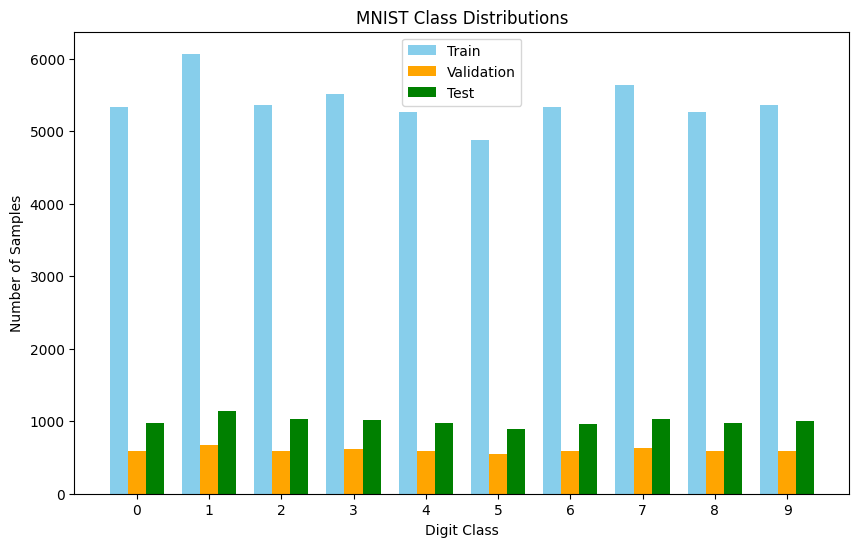

In [17]:
plot_class_distributions(y_train_new, y_val_new, y_test)

In [18]:
relative_imbalance(y_train_new)

np.float64(2.2016887637952745)

In [19]:
# note: shitty results 

# X_train_new = X_train_new.astype(np.float32) / 255.0
# X_val_new = X_val_new.astype(np.float32) / 255.0
# X_test = X_test.astype(np.float32) / 255.0

# Modular neural network

In [20]:
import numpy as np
from dataclasses import dataclass, field, asdict


# =========================================================
# Configs
# =========================================================
@dataclass
class RegularizationConfig:
    l2_lambda: float = 0.0
    early_stopping: bool = False
    patience: int = 5
    min_delta: float = 0.0
    restore_best_weights: bool = True

@dataclass
class ArchitectureConfig:
    layer_sizes: list                 # example: [4, 16, 8, 3]
    activations: list                 # example: ["relu", "tanh", "softmax"]
    weight_inits: object = "xavier"   # str, dict, or list


@dataclass
class TrainingConfig:
    epochs: int = 100
    batch_size: int = 32
    learning_rate: float = 0.01
    optimizer: str = "sgd"            # "sgd" or "sgd_momentum"
    momentum: float = 0.9
    shuffle: bool = True


@dataclass
class PreprocessingConfig:
    standardize: bool = False


@dataclass
class ModelConfig:
    architecture: ArchitectureConfig
    training: TrainingConfig = field(default_factory=TrainingConfig)
    preprocessing: PreprocessingConfig = field(default_factory=PreprocessingConfig)
    regularization: RegularizationConfig = field(default_factory=RegularizationConfig)
    loss: str = "categorical_crossentropy"
    seed: int | None = None


# =========================================================
# Initializers
# =========================================================
class Initializer:
    @staticmethod
    def create(shape, init_cfg="xavier", rng=None):
        if rng is None:
            rng = np.random.default_rng()

        fan_in, fan_out = shape

        if callable(init_cfg):
            W = init_cfg(shape, rng)
            return np.asarray(W, dtype=float)

        if isinstance(init_cfg, str):
            init_cfg = {"type": init_cfg}

        init_type = init_cfg.get("type", "xavier").lower()

        if init_type == "xavier":
            limit = np.sqrt(6.0 / (fan_in + fan_out))
            return rng.uniform(-limit, limit, size=shape)

        elif init_type == "he":
            std = np.sqrt(2.0 / fan_in)
            return rng.normal(0.0, std, size=shape)

        elif init_type == "normal":
            mean = init_cfg.get("mean", 0.0)
            std = init_cfg.get("std", 0.01)
            return rng.normal(mean, std, size=shape)

        elif init_type == "uniform":
            low = init_cfg.get("low", -0.1)
            high = init_cfg.get("high", 0.1)
            return rng.uniform(low, high, size=shape)

        else:
            raise ValueError(f"Unknown weight initializer: {init_type}")


# =========================================================
# Preprocessing
# =========================================================
class StandardScaler:
    def __init__(self):
        self.mean = None
        self.std = None

    def fit(self, X):
        self.mean = np.mean(X, axis=0, keepdims=True)
        self.std = np.std(X, axis=0, keepdims=True)
        self.std[self.std == 0] = 1.0

    def transform(self, X):
        if self.mean is None or self.std is None:
            raise ValueError("Scaler has not been fitted yet.")
        return (X - self.mean) / self.std

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)


# =========================================================
# Activations
# =========================================================
class Activation:
    def forward(self, z):
        raise NotImplementedError

    def backward(self, grad_output):
        raise NotImplementedError


class ReLU(Activation):
    def forward(self, z):
        self.z = z
        return np.maximum(0, z)

    def backward(self, grad_output):
        return grad_output * (self.z > 0)


class Sigmoid(Activation):
    def forward(self, z):
        self.a = 1.0 / (1.0 + np.exp(-z))
        return self.a

    def backward(self, grad_output):
        return grad_output * self.a * (1 - self.a)


class Tanh(Activation):
    def forward(self, z):
        self.a = np.tanh(z)
        return self.a

    def backward(self, grad_output):
        return grad_output * (1 - self.a**2)


class Linear(Activation):
    def forward(self, z):
        return z

    def backward(self, grad_output):
        return grad_output


class Softmax(Activation):
    def forward(self, z):
        z_shifted = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(z_shifted)
        self.a = exp_z / np.sum(exp_z, axis=1, keepdims=True)
        return self.a

    def backward(self, grad_output):
        # We do not use the full Jacobian here.
        # This works correctly when Softmax is paired with CrossEntropy.
        return grad_output


def get_activation(name):
    name = name.lower()
    if name == "relu":
        return ReLU()
    if name == "sigmoid":
        return Sigmoid()
    if name == "tanh":
        return Tanh()
    if name == "linear":
        return Linear()
    if name == "softmax":
        return Softmax()
    raise ValueError(f"Unknown activation: {name}")


# =========================================================
# Layers
# =========================================================
class Layer:
    def forward(self, x):
        raise NotImplementedError

    def backward(self, grad_output):
        raise NotImplementedError

    def parameters(self):
        return []


class Dense(Layer):
    def __init__(self, in_features, out_features, weight_init="xavier", rng=None):
        self.rng = rng if rng is not None else np.random.default_rng()
        self.W = Initializer.create((in_features, out_features), weight_init, self.rng)
        self.b = np.zeros((1, out_features))

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, x):
        self.input = x
        return x @ self.W + self.b

    def backward(self, grad_output, l2_lambda=0.0):
        batch_size = self.input.shape[0]
        self.dW = (self.input.T @ grad_output) / batch_size

        if l2_lambda > 0:
            self.dW += l2_lambda * self.W

        self.db = np.sum(grad_output, axis=0, keepdims=True) / batch_size
        grad_input = grad_output @ self.W.T
        return grad_input

    def parameters(self):
        return [
            {"param": self.W, "grad": self.dW},
            {"param": self.b, "grad": self.db},
        ]


class ActivationLayer(Layer):
    def __init__(self, activation):
        self.activation_name = activation.lower()
        self.activation = get_activation(activation)

    def forward(self, x):
        return self.activation.forward(x)

    def backward(self, grad_output):
        return self.activation.backward(grad_output)


# =========================================================
# Losses
# =========================================================
class Loss:
    def forward(self, y_pred, y_true):
        raise NotImplementedError

    def backward(self):
        raise NotImplementedError


class CategoricalCrossEntropy(Loss):
    def forward(self, y_pred, y_true):
        self.y_pred = np.clip(y_pred, 1e-12, 1.0 - 1e-12)

        if y_true.ndim == 1:
            self.y_true = np.zeros_like(self.y_pred)
            self.y_true[np.arange(len(y_true)), y_true] = 1.0
        else:
            self.y_true = y_true

        return -np.mean(np.sum(self.y_true * np.log(self.y_pred), axis=1))

    def backward(self):
        # paired with softmax output
        return self.y_pred - self.y_true


class MSE(Loss):
    def forward(self, y_pred, y_true):
        self.y_pred = y_pred
        self.y_true = y_true
        return np.mean((y_pred - y_true) ** 2)

    def backward(self):
        return 2 * (self.y_pred - self.y_true) / self.y_true.shape[0]


def get_loss(name):
    name = name.lower()
    if name in ("categorical_crossentropy", "crossentropy", "ce"):
        return CategoricalCrossEntropy()
    if name == "mse":
        return MSE()
    raise ValueError(f"Unknown loss: {name}")


# =========================================================
# Optimizers
# =========================================================
class Optimizer:
    def step(self, layers):
        raise NotImplementedError


class SGD(Optimizer):
    def __init__(self, learning_rate=0.01):
        self.learning_rate = learning_rate

    def step(self, layers):
        for layer in layers:
            for p in layer.parameters():
                p["param"] -= self.learning_rate * p["grad"]


class SGDMomentum(Optimizer):
    def __init__(self, learning_rate=0.01, momentum=0.9):
        self.learning_rate = learning_rate
        self.momentum = momentum
        self.velocity = {}

    def step(self, layers):
        for layer in layers:
            for p in layer.parameters():
                key = id(p["param"])
                if key not in self.velocity:
                    self.velocity[key] = np.zeros_like(p["param"])

                self.velocity[key] = (
                    self.momentum * self.velocity[key]
                    - self.learning_rate * p["grad"]
                )
                p["param"] += self.velocity[key]


def get_optimizer(name, learning_rate=0.01, momentum=0.9):
    name = name.lower()
    if name == "sgd":
        return SGD(learning_rate=learning_rate)
    if name in ("sgd_momentum", "momentum"):
        return SGDMomentum(learning_rate=learning_rate, momentum=momentum)
    raise ValueError(f"Unknown optimizer: {name}")


# =========================================================
# Neural Network
# =========================================================
class NeuralNetwork:
    def __init__(self, config: ModelConfig):
        self.config = config
        self.rng = np.random.default_rng(config.seed)
        self.loss_fn = get_loss(config.loss)
        self.optimizer = get_optimizer(
            config.training.optimizer,
            learning_rate=config.training.learning_rate,
            momentum=config.training.momentum,
        )

        self.scaler = StandardScaler() if config.preprocessing.standardize else None
        self.layers = self._build_from_config()

        self._validate_configuration()

    def _validate_configuration(self):
        arch = self.config.architecture

        if len(arch.layer_sizes) < 2:
            raise ValueError("layer_sizes must contain at least input and output layer.")

        if len(arch.activations) != len(arch.layer_sizes) - 1:
            raise ValueError("activations length must equal len(layer_sizes) - 1.")

        if "softmax" in [a.lower() for a in arch.activations[:-1]]:
            raise ValueError("softmax should only appear on the output layer.")

        if arch.activations[-1].lower() == "softmax" and self.config.loss.lower() == "mse":
            raise ValueError("Softmax output is intended to be used with categorical cross-entropy.")

    def _get_weight_init_for_layer(self, layer_idx):
        weight_inits = self.config.architecture.weight_inits

        if isinstance(weight_inits, list):
            if len(weight_inits) != len(self.config.architecture.layer_sizes) - 1:
                raise ValueError("weight_inits list must have one entry per Dense layer.")
            return weight_inits[layer_idx]

        return weight_inits

    def _build_from_config(self):
        arch = self.config.architecture
        layers = []

        for i in range(len(arch.layer_sizes) - 1):
            in_features = arch.layer_sizes[i]
            out_features = arch.layer_sizes[i + 1]
            activation = arch.activations[i]
            weight_init = self._get_weight_init_for_layer(i)

            layers.append(
                Dense(
                    in_features=in_features,
                    out_features=out_features,
                    weight_init=weight_init,
                    rng=self.rng,
                )
            )
            layers.append(ActivationLayer(activation))

        return layers

    def _transform_input(self, X, fit=False):
        if self.scaler is None:
            return X
        if fit:
            return self.scaler.fit_transform(X)
        return self.scaler.transform(X)

    def _get_model_state(self):
        state = []
        for layer in self.layers:
            if isinstance(layer, Dense):
                state.append({
                    "W": layer.W.copy(),
                    "b": layer.b.copy(),
                })
        return state

    def _set_model_state(self, state):
        idx = 0
        for layer in self.layers:
            if isinstance(layer, Dense):
                layer.W[...] = state[idx]["W"]
                layer.b[...] = state[idx]["b"]
                idx += 1

    def forward(self, X):
        out = X
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def backward(self, grad_loss):
        grad = grad_loss
        l2_lambda = self.config.regularization.l2_lambda

        for layer in reversed(self.layers):
            if isinstance(layer, Dense):
                grad = layer.backward(grad, l2_lambda=l2_lambda)
            else:
                grad = layer.backward(grad)

    def predict_proba(self, X):
        X = self._transform_input(X, fit=False)
        return self.forward(X)

    def predict(self, X):
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

    def accuracy(self, X, y):
        preds = self.predict(X)
        if y.ndim == 2:
            y = np.argmax(y, axis=1)
        return np.mean(preds == y)

    def fit(self, X, y, X_val=None, y_val=None, verbose=True):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        X_train = self._transform_input(X, fit=True)

        X_val_proc = None
        if X_val is not None:
            X_val = np.asarray(X_val, dtype=float)
            X_val_proc = self._transform_input(X_val, fit=False)

        n_samples = X_train.shape[0]
        epochs = self.config.training.epochs
        batch_size = self.config.training.batch_size
        shuffle = self.config.training.shuffle

        reg_cfg = self.config.regularization

        if batch_size <= 0 or batch_size > n_samples:
            batch_size = n_samples

        history = {
            "loss": [],
            "acc": [],
            "val_loss": [],
            "val_acc": [],
        }

        best_val_loss = np.inf
        best_epoch = 0
        best_state = None
        epochs_without_improvement = 0

        for epoch in range(epochs):
            if shuffle:
                indices = self.rng.permutation(n_samples)
                X_epoch = X_train[indices]
                y_epoch = y[indices]
            else:
                X_epoch = X_train
                y_epoch = y

            for start in range(0, n_samples, batch_size):
                end = start + batch_size
                xb = X_epoch[start:end]
                yb = y_epoch[start:end]

                y_pred = self.forward(xb)
                _ = self.loss_fn.forward(y_pred, yb)
                grad_loss = self.loss_fn.backward()

                self.backward(grad_loss)
                self.optimizer.step(self.layers)

            train_pred = self.forward(X_train)
            train_loss = self.loss_fn.forward(train_pred, y)

            if y.ndim == 2:
                y_train_labels = np.argmax(y, axis=1)
            else:
                y_train_labels = y
            train_pred_labels = np.argmax(train_pred, axis=1)
            train_acc = np.mean(train_pred_labels == y_train_labels)

            history["loss"].append(train_loss)
            history["acc"].append(train_acc)

            msg = f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - acc: {train_acc:.4f}"

            if X_val_proc is not None and y_val is not None:
                val_pred = self.forward(X_val_proc)
                val_loss = self.loss_fn.forward(val_pred, y_val)

                if y_val.ndim == 2:
                    y_val_labels = np.argmax(y_val, axis=1)
                else:
                    y_val_labels = y_val
                val_pred_labels = np.argmax(val_pred, axis=1)
                val_acc = np.mean(val_pred_labels == y_val_labels)

                history["val_loss"].append(val_loss)
                history["val_acc"].append(val_acc)

                msg += f" - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}"

                if reg_cfg.early_stopping:
                    if val_loss < best_val_loss - reg_cfg.min_delta:
                        best_val_loss = val_loss
                        best_epoch = epoch + 1
                        best_state = self._get_model_state()
                        epochs_without_improvement = 0
                    else:
                        epochs_without_improvement += 1

            if verbose:
                print(msg)

            if X_val_proc is not None and y_val is not None and reg_cfg.early_stopping:
                if epochs_without_improvement >= reg_cfg.patience:
                    if reg_cfg.restore_best_weights and best_state is not None:
                        self._set_model_state(best_state)
                    if verbose:
                        print(f"Early stopping at epoch {epoch+1}. Restored best weights from epoch {best_epoch}.")
                    break

        return history

    def save(self, file_path, history=None):
        model_state = []
        for layer in self.layers:
            if isinstance(layer, Dense):
                model_state.append({
                    "W": layer.W.copy(),
                    "b": layer.b.copy(),
                })

        scaler_state = None
        if self.scaler is not None:
            scaler_state = {
                "mean": None if self.scaler.mean is None else self.scaler.mean.copy(),
                "std": None if self.scaler.std is None else self.scaler.std.copy(),
            }

        payload = {
            "config": asdict(self.config),
            "model_state": model_state,
            "scaler_state": scaler_state,
            "history": history,
        }

        with open(file_path, "wb") as f:
            pickle.dump(payload, f)

        print(f"Model saved to {file_path}")

    @classmethod
    def load(cls, file_path):
        with open(file_path, "rb") as f:
            payload = pickle.load(f)

        cfg = payload["config"]
        config = ModelConfig(
            architecture=ArchitectureConfig(**cfg["architecture"]),
            training=TrainingConfig(**cfg["training"]),
            preprocessing=PreprocessingConfig(**cfg["preprocessing"]),
            regularization=RegularizationConfig(**cfg["regularization"]),
            loss=cfg.get("loss", "categorical_crossentropy"),
            seed=cfg.get("seed", None),
        )

        model = cls(config)
        model._set_model_state(payload["model_state"])

        scaler_state = payload.get("scaler_state")
        if model.scaler is not None and scaler_state is not None:
            model.scaler.mean = scaler_state["mean"]
            model.scaler.std = scaler_state["std"]

        history = payload.get("history")
        print(f"Model loaded from {file_path}")
        return model, history

In [21]:
config = ModelConfig(
    architecture=ArchitectureConfig(
        layer_sizes=[784, 64, 10],                 # number of layers + neurons
        activations=["relu", "softmax"],           # activation per layer
        weight_inits=[                       # init per Dense layer
            {"type": "normal", "mean": 0.0, "std": 1},
            {"type": "normal", "mean": 0.0, "std": 1},
        ],
    ),
    training=TrainingConfig(
        epochs=50,
        batch_size=16,
        learning_rate=0.01,
        optimizer="sgd_momentum",
        momentum=0.9,
        shuffle=True,
    ),
    preprocessing=PreprocessingConfig(
        standardize=False
    ),
    regularization=RegularizationConfig(
        l2_lambda=1e-4,
        early_stopping=False,
        patience=6,
        min_delta=1e-4,
        restore_best_weights=True,
    ),
    loss="categorical_crossentropy",
    seed=42,
)

model = NeuralNetwork(config)
history = model.fit(
    X_train_new, 
    y_train_new, 
    X_val_new,
    y_val_new, 
    verbose=True)

preds = model.predict(X_test)
acc = model.accuracy(X_test, y_test)
print("Test accuracy:", acc)

Epoch 1/50 - loss: 0.4953 - acc: 0.8595 - val_loss: 0.5422 - val_acc: 0.8549
Epoch 2/50 - loss: 0.3527 - acc: 0.8965 - val_loss: 0.4104 - val_acc: 0.8886
Epoch 3/50 - loss: 0.3390 - acc: 0.8965 - val_loss: 0.4138 - val_acc: 0.8811
Epoch 4/50 - loss: 0.2500 - acc: 0.9279 - val_loss: 0.3212 - val_acc: 0.9143
Epoch 5/50 - loss: 0.2132 - acc: 0.9363 - val_loss: 0.2815 - val_acc: 0.9189
Epoch 6/50 - loss: 0.1969 - acc: 0.9430 - val_loss: 0.2747 - val_acc: 0.9275
Epoch 7/50 - loss: 0.1773 - acc: 0.9462 - val_loss: 0.2511 - val_acc: 0.9281
Epoch 8/50 - loss: 0.1729 - acc: 0.9488 - val_loss: 0.2569 - val_acc: 0.9298
Epoch 9/50 - loss: 0.1601 - acc: 0.9530 - val_loss: 0.2433 - val_acc: 0.9345
Epoch 10/50 - loss: 0.1441 - acc: 0.9562 - val_loss: 0.2203 - val_acc: 0.9396
Epoch 11/50 - loss: 0.1221 - acc: 0.9639 - val_loss: 0.2059 - val_acc: 0.9403
Epoch 12/50 - loss: 0.1193 - acc: 0.9638 - val_loss: 0.2034 - val_acc: 0.9428
Epoch 13/50 - loss: 0.1116 - acc: 0.9667 - val_loss: 0.1941 - val_acc: 0.

In [22]:
# Save the trained model
model.save("mnist_model.pkl", history=history)

# Load it back later
loaded_model, loaded_history = NeuralNetwork.load("mnist_model.pkl")

# Quick check
loaded_acc = loaded_model.accuracy(X_test, y_test)
print("Loaded model test accuracy:", loaded_acc)

Model saved to mnist_model.pkl
Model loaded from mnist_model.pkl
Loaded model test accuracy: 0.9688


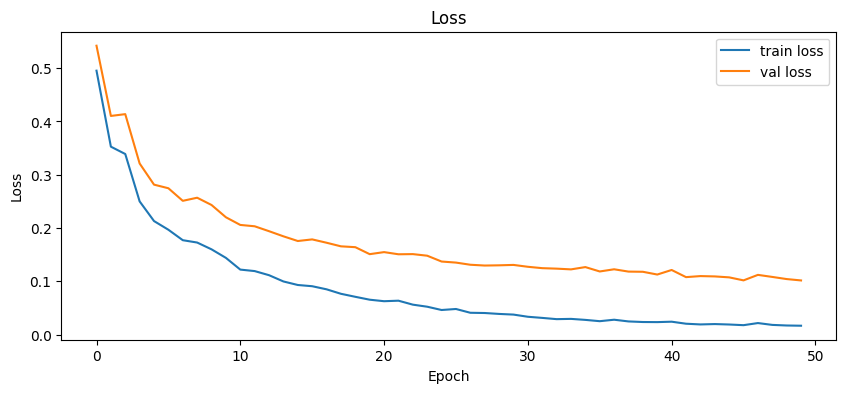

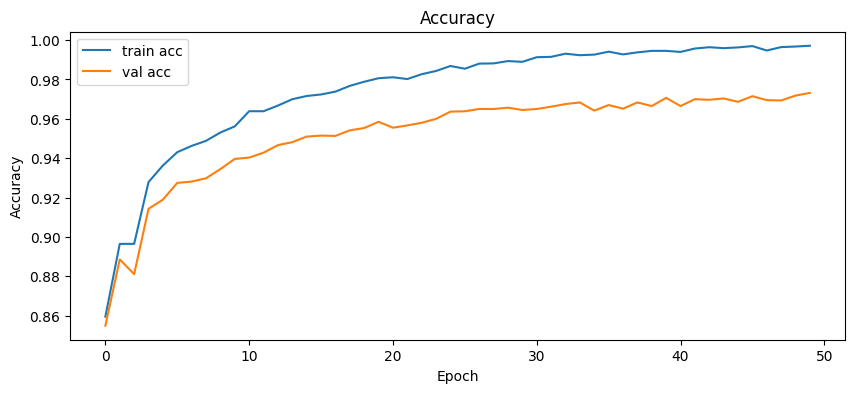

In [23]:
plt.figure(figsize=(10, 4))
plt.plot(history["loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(history["acc"], label="train acc")
plt.plot(history["val_acc"], label="val acc")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.show()

In [ ]:
def to_labels(y):
    y = np.asarray(y)
    if y.ndim == 2:
        return np.argmax(y, axis=1)
    return y


def build_confusion_matrix(y_true, y_pred, num_classes=10):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm


def per_class_accuracy(cm):
    class_totals = cm.sum(axis=1)
    acc = np.zeros(len(class_totals), dtype=float)

    for i in range(len(class_totals)):
        if class_totals[i] > 0:
            acc[i] = cm[i, i] / class_totals[i]
    return acc


def top_confusion_pairs(cm, top_k=5, symmetric=True):
    pairs = []

    if symmetric:
        # combine i->j and j->i
        for i in range(cm.shape[0]):
            for j in range(i + 1, cm.shape[1]):
                count = cm[i, j] + cm[j, i]
                pairs.append((i, j, count))
        pairs.sort(key=lambda x: x[2], reverse=True)
    else:
        # directional: true i predicted as j
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                if i != j:
                    pairs.append((i, j, cm[i, j]))
        pairs.sort(key=lambda x: x[2], reverse=True)

    return pairs[:top_k]


def plot_confusion_matrix(cm, class_names=None, title="Confusion Matrix"):
    num_classes = cm.shape[0]
    if class_names is None:
        class_names = list(range(num_classes))

    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation="nearest", cmap="Blues")
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(num_classes)
    plt.xticks(tick_marks, class_names)
    plt.yticks(tick_marks, class_names)

    plt.xlabel("Predicted label")
    plt.ylabel("True label")

    for i in range(num_classes):
        for j in range(num_classes):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center", color="black")

    plt.tight_layout()
    plt.show()


def plot_misclassified_examples(X, y_true, y_pred, n=12, img_shape=(28, 28), shuffle=True):
    wrong_idx = np.where(y_true != y_pred)[0]

    if len(wrong_idx) == 0:
        print("No misclassified examples found.")
        return

    if shuffle:
        np.random.shuffle(wrong_idx)

    n = min(n, len(wrong_idx))
    cols = 4
    rows = int(np.ceil(n / cols))

    plt.figure(figsize=(12, 3 * rows))

    for k, idx in enumerate(wrong_idx[:n]):
        plt.subplot(rows, cols, k + 1)

        img = X[idx]
        if img.ndim == 1:
            img = img.reshape(img_shape)

        plt.imshow(img, cmap="gray")
        plt.title(f"True: {y_true[idx]} | Pred: {y_pred[idx]}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


def analyze_model_predictions(model, X, y, num_classes=10, class_names=None,
                              img_shape=(28, 28), n_wrong_to_plot=12,
                              confusion_top_k=5, split_name="Dataset"):
    y_true = to_labels(y)
    y_pred = model.predict(X)

    cm = build_confusion_matrix(y_true, y_pred, num_classes=num_classes)
    class_acc = per_class_accuracy(cm)

    overall_acc = np.mean(y_true == y_pred)
    worst_class = int(np.argmin(class_acc))

    # Most common wrong prediction(s) for the worst class
    worst_row = cm[worst_class].copy()
    worst_row[worst_class] = 0
    most_confused_with = np.argsort(worst_row)[::-1]

    print(f"\n=== {split_name} analysis ===")
    print(f"Overall accuracy: {overall_acc:.4f}\n")

    print("1) Accuracy for each class:")
    for i, acc in enumerate(class_acc):
        label = class_names[i] if class_names is not None else i
        print(f"Class {label}: {acc:.4f} ({acc*100:.2f}%)")

    print("\n2) Worst classified class:")
    worst_label = class_names[worst_class] if class_names is not None else worst_class
    print(f"Class {worst_label} with accuracy {class_acc[worst_class]:.4f} ({class_acc[worst_class]*100:.2f}%)")

    top_wrong = [(j, worst_row[j]) for j in most_confused_with[:3] if worst_row[j] > 0]
    if top_wrong:
        print("Most often mistaken as:")
        for j, count in top_wrong:
            pred_label = class_names[j] if class_names is not None else j
            print(f"  predicted as {pred_label}: {count} times")

        confused_labels = ", ".join(str(class_names[j] if class_names is not None else j) for j, _ in top_wrong)
    else:
        print("No significant misclassifications found for that class.")

    print("\n3) Classes mistaken with each other most:")
    top_pairs = top_confusion_pairs(cm, top_k=confusion_top_k, symmetric=True)
    for i, j, count in top_pairs:
        label_i = class_names[i] if class_names is not None else i
        label_j = class_names[j] if class_names is not None else j
        print(f"Classes {label_i} and {label_j}: {count} mutual confusions")

    if top_pairs and top_pairs[0][2] > 0:
        i, j, count = top_pairs[0]
        label_i = class_names[i] if class_names is not None else i
        label_j = class_names[j] if class_names is not None else j

    print("\n4) Plotting misclassified examples...")
    plot_misclassified_examples(X, y_true, y_pred, n=n_wrong_to_plot, img_shape=img_shape)

    print("\nConfusion matrix:")
    plot_confusion_matrix(cm, class_names=class_names, title=f"{split_name} Confusion Matrix")

    return {
        "overall_accuracy": overall_acc,
        "y_true": y_true,
        "y_pred": y_pred,
        "confusion_matrix": cm,
        "per_class_accuracy": class_acc,
        "worst_class": worst_class,
        "top_confusions": top_pairs,
    }


=== Test Set analysis ===
Overall accuracy: 0.9688

1) Accuracy for each class:
Class 0: 0.9867 (98.67%)
Class 1: 0.9885 (98.85%)
Class 2: 0.9603 (96.03%)
Class 3: 0.9663 (96.63%)
Class 4: 0.9735 (97.35%)
Class 5: 0.9697 (96.97%)
Class 6: 0.9749 (97.49%)
Class 7: 0.9533 (95.33%)
Class 8: 0.9682 (96.82%)
Class 9: 0.9455 (94.55%)

2) Worst classified class:
Class 9 with accuracy 0.9455 (94.55%)
Most often mistaken as:
  predicted as 4: 16 times
  predicted as 8: 10 times
  predicted as 3: 8 times
Why? Likely because class 9 shares visual patterns with 4, 8, 3 in handwriting.

3) Classes mistaken with each other most:
Classes 4 and 9: 26 mutual confusions
Classes 3 and 5: 23 mutual confusions
Classes 2 and 7: 21 mutual confusions
Classes 2 and 8: 17 mutual confusions
Classes 7 and 9: 17 mutual confusions
Why? These two classes likely have the most similar handwritten shapes/strokes.

4) Plotting misclassified examples...


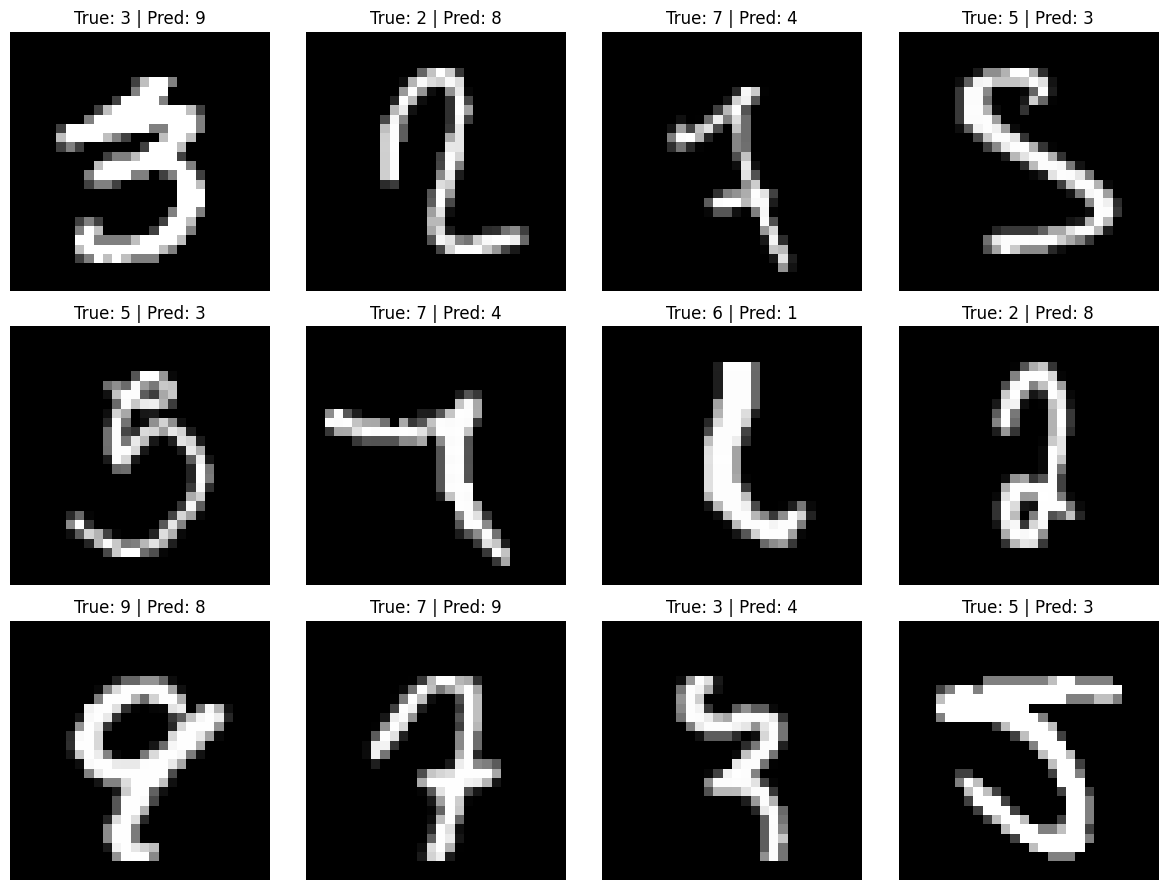


Confusion matrix:


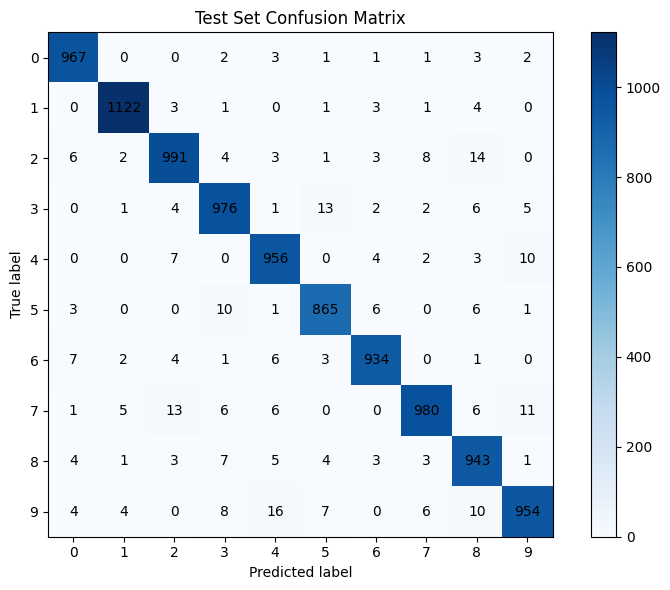

In [25]:
results = analyze_model_predictions(
    model,
    X_test,
    y_test,
    num_classes=10,
    class_names=list(range(10)),
    img_shape=(28, 28),
    n_wrong_to_plot=12,
    confusion_top_k=5,
    split_name="Test Set"
)


=== Validation Set analysis ===
Overall accuracy: 0.9731

1) Accuracy for each class:
Class 0: 0.9916 (99.16%)
Class 1: 0.9822 (98.22%)
Class 2: 0.9748 (97.48%)
Class 3: 0.9641 (96.41%)
Class 4: 0.9777 (97.77%)
Class 5: 0.9465 (94.65%)
Class 6: 0.9882 (98.82%)
Class 7: 0.9696 (96.96%)
Class 8: 0.9641 (96.41%)
Class 9: 0.9697 (96.97%)

2) Worst classified class:
Class 5 with accuracy 0.9465 (94.65%)
Most often mistaken as:
  predicted as 3: 7 times
  predicted as 8: 6 times
  predicted as 9: 5 times
Why? Likely because class 5 shares visual patterns with 3, 8, 9 in handwriting.

3) Classes mistaken with each other most:
Classes 4 and 9: 17 mutual confusions
Classes 3 and 5: 15 mutual confusions
Classes 5 and 8: 10 mutual confusions
Classes 2 and 3: 9 mutual confusions
Classes 7 and 9: 9 mutual confusions
Why? These two classes likely have the most similar handwritten shapes/strokes.

4) Plotting misclassified examples...


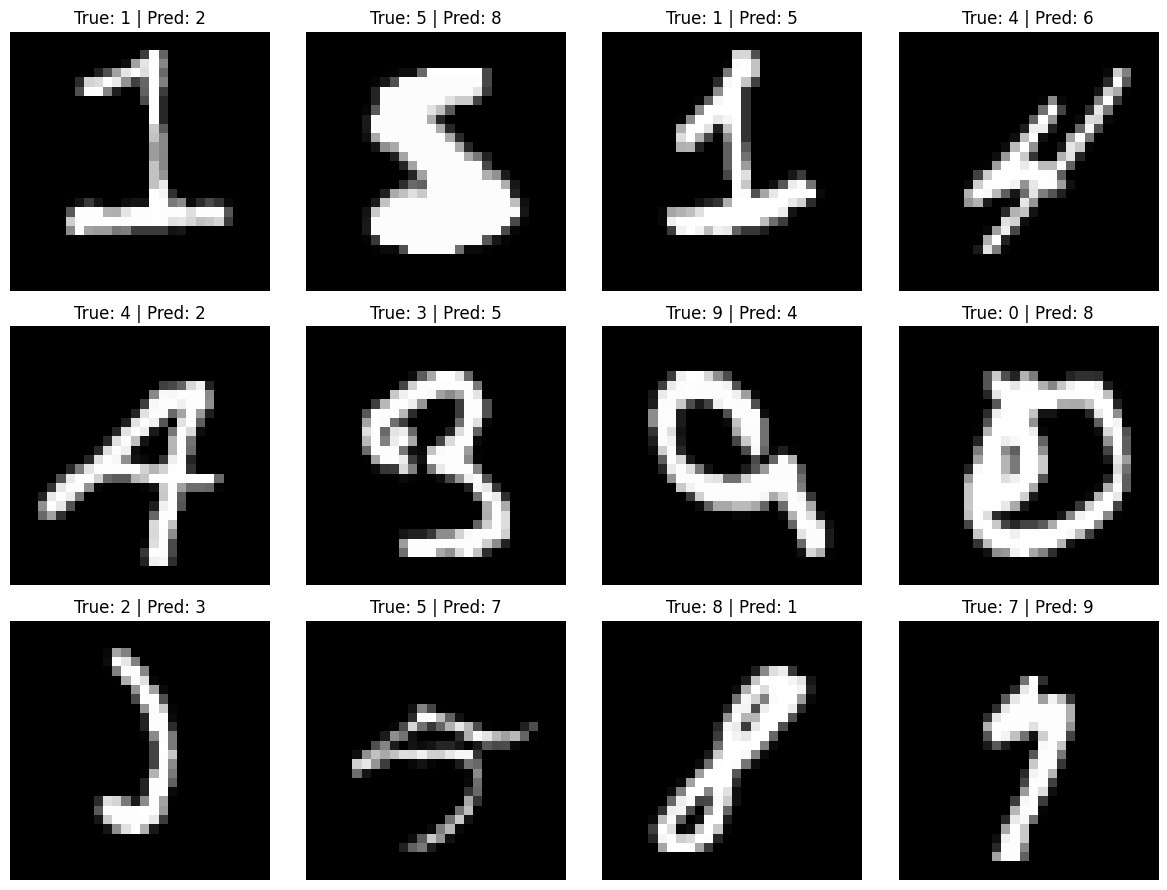


Confusion matrix:


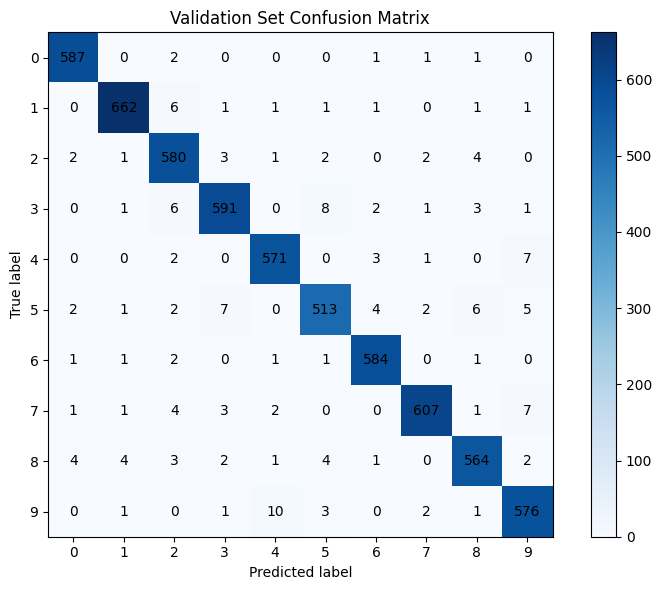

In [26]:
results = analyze_model_predictions(
    model,
    X_val_new,
    y_val_new,
    num_classes=10,
    class_names=list(range(10)),
    img_shape=(28, 28),
    n_wrong_to_plot=12,
    confusion_top_k=5,
    split_name="Validation Set"
)